In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.morphology import skeletonize

In [4]:
img = cv2.imread("images.jpg", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

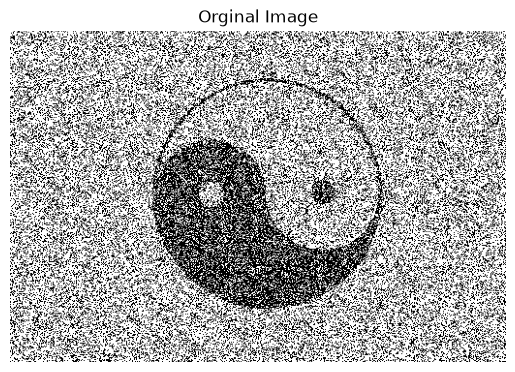

In [5]:
plt.imshow(binary, cmap="gray")
plt.title("Orginal Image")
plt.axis("off")
plt.show()

In [6]:
kernel = np.ones((3,3), np.uint8)
kernel_area = kernel.sum()

In [7]:
binary_ones = (binary / 255).astype(np.float32)

In [8]:
neighborhood_sum = cv2.filter2D(binary_ones, -1, kernel)
eroded_manual = np.where(neighborhood_sum >= kernel_area - 0.5, 255, 0)
eroded_manual = eroded_manual.astype(np.uint8)

In [9]:
eroded_cv2 = cv2.erode(binary, kernel, iterations=1)

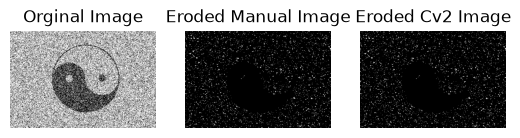

In [12]:
plt.subplot(1,3,1)
plt.imshow(binary, cmap="gray")
plt.title("Orginal Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(eroded_manual, cmap="gray")
plt.title("Eroded Manual Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(eroded_cv2, cmap="gray")
plt.title("Eroded Cv2 Image")
plt.axis("off")

plt.show()

In [13]:
dilated_manual = np.where(neighborhood_sum > 0.5, 255, 0)
dilated_manual = dilated_manual.astype(np.uint8)

In [14]:
dilated_cv2 = cv2.dilate(binary, kernel, iterations=1)

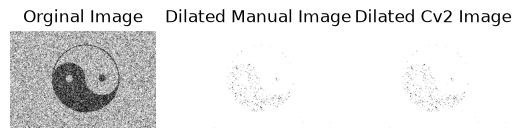

In [15]:
plt.subplot(1,3,1)
plt.imshow(binary, cmap="gray")
plt.title("Orginal Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(dilated_manual, cmap="gray")
plt.title("Dilated Manual Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(dilated_cv2, cmap="gray")
plt.title("Dilated Cv2 Image")
plt.axis("off")

plt.show()

In [19]:
opened_cv2 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed_cv2 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

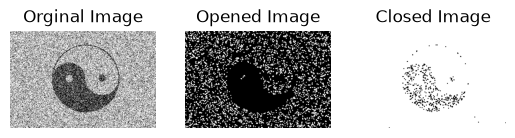

In [24]:
plt.subplot(1,3,1)
plt.imshow(binary, cmap="gray")
plt.title("Orginal Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(opened_cv2, cmap="gray")
plt.title("Opened Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(closed_cv2, cmap="gray")
plt.title("Closed Image")
plt.axis("off")

plt.show()

In [29]:
cleaned = opened_cv2
boundary = cv2.subtract(cleaned, cv2.erode(cleaned, kernel, iterations=1))

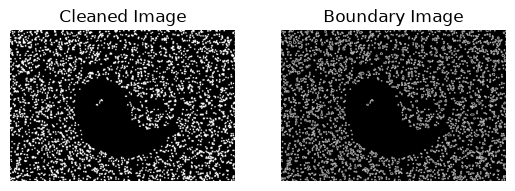

In [31]:
plt.subplot(1,2,1)
plt.imshow(cleaned, cmap="gray")
plt.title("Cleaned Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(boundary, cmap="gray")
plt.title("Boundary Image")
plt.axis("off")

plt.show()

In [32]:
binary_bool = cleaned > 0
skeleton = skeletonize(binary_bool)
skeleton_display = (skeleton * 255).astype(np.uint8)

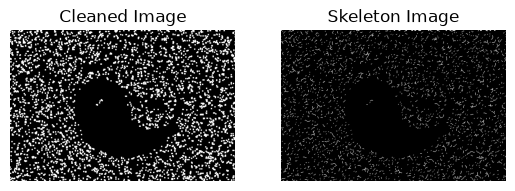

In [34]:
plt.subplot(1,2,1)
plt.imshow(cleaned, cmap="gray")
plt.title("Cleaned Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(skeleton_display, cmap="gray")
plt.title("Skeleton Image")
plt.axis("off")

plt.show()